# Лабораторная работа 1 — рабочий ноутбук

**ФИО: Диденко Никита Валерьевич**

**Файлы данных: S09** `clients.csv`, `transactions.csv`

Этот ноутбук — чистовой рабочий документ, а не черновик. Он должен
исполняться сверху вниз без ошибок на выданном вам **сыром** файле
и на выходе давать очищенную таблицу и `cleaning_log.csv`.

Разделы ниже обязательны, порядок менять не нужно. Внутри раздела
добавляйте столько ячеек, сколько нужно. Если какой-то раздел у вас
пустой — напишите в нём одной строкой, почему.

## 0. Окружение и настройки

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 50)

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["DejaVu Sans", "Arial"]
plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 10

RAW_CLIENTS = "clients.csv"
RAW_TXN = "transactions.csv"

## 1. Загрузка сырых данных

Файлы выгружены разными системами. Убедитесь, что они прочитались
**правильно**: кодировка, разделитель, десятичный разделитель, типы,
даты, идентификаторы.

In [3]:
df_clients_raw = pd.read_csv(RAW_CLIENTS)
print(f"clients.csv: {df_clients_raw.shape[0]} строки, {df_clients_raw.shape[1]} столбцов")

df_txn_raw = pd.read_csv(RAW_TXN, sep=";", decimal=",", encoding="cp1251")
print(f"transactions.csv: {df_txn_raw.shape[0]} строки, {df_txn_raw.shape[1]} столбцов")

display(df_clients_raw.head(3))
display(df_txn_raw.head(3))

clients.csv: 5733 строки, 16 столбцов
transactions.csv: 625604 строки, 9 столбцов


,client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in
0,C001526,1963-05-16,М,Санкт-Петербург,Массовый,Базовый,Кредитная,15.03.2015,06.03.2018,Зарплата в нашем банке,58900.0,Нет,NaN,3.0,335,Да
1,C002932,1955-05-17,М,Нижний Новгород,Массовый,Базовый,Дебетовая,23.05.2011,09.03.2016,Зарплата в нашем банке,53700.0,Да,2024-01,4.0,713,Да
2,C001462,1994-10-08,М,Санкт-Петербург,Зарплатный,Серебро,Дебетовая,25.04.2020,22.04.2025,Зарплата в нашем банке,54500.0,Нет,NaN,1.0,279,Нет


,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,channel,status
0,990050,C003010,2023-12-15,473.34,RUB,Связь и интернет,4814,Карта,успешно
1,990083,C003001,2023-12-17,167.44,RUB,Транспорт,4111,СБП,успешно
2,990039,C003369,2023-12-18 19:14:40,543.82,RUB,Онлайн-сервисы,5815,Карта,успешно


## 2. Аудит качества

Здесь вы ничего не исправляете — только находите и измеряете.
Для каждой метрики качества заранее определите знаменатель.

### 2.1. Объём, типы, ключи, единица наблюдения

In [4]:
print("CLIENTS")
print(df_clients_raw.info())
print("\nУникальных client_id:", df_clients_raw['client_id'].nunique(), "из", len(df_clients_raw))
print("Единица наблюдения clients.csv: клиент банка")

print("\nTRANSACTIONS")
print(df_txn_raw.info())
print("\nУникальных txn_id:", df_txn_raw['txn_id'].nunique(), "из", len(df_txn_raw))
print("Единица наблюдения transactions.csv: операция по карте")


CLIENTS
<class 'pandas.DataFrame'>
RangeIndex: 5733 entries, 0 to 5732
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   client_id           5733 non-null   str    
 1   birth_date          5733 non-null   str    
 2   gender              5733 non-null   str    
 3   city                5733 non-null   str    
 4   segment             5733 non-null   str    
 5   loyalty_tier        5733 non-null   str    
 6   card_type           5733 non-null   str    
 7   registration_date   5733 non-null   str    
 8   card_open_date      5733 non-null   str    
 9   income_source       5733 non-null   str    
 10  monthly_income      5199 non-null   float64
 11  has_mobile_app      5733 non-null   str    
 12  app_last_login      3525 non-null   str    
 13  satisfaction_score  2267 non-null   float64
 14  branch_code         5733 non-null   int64  
 15  marketing_opt_in    5733 non-null   str    
dtypes: float6

### 2.2. Дубли

In [5]:
n_client_dups = int(df_clients_raw['client_id'].duplicated().sum())

print(f"В clients.csv {n_client_dups} дублирующих записей с повторяющимся client_id, из которых {df_clients_raw.duplicated().sum()} полных строк-дубликатов и {n_client_dups - df_clients_raw.duplicated().sum()} неполных строк-дубликатов.")

n_txn_dups = int(df_txn_raw['txn_id'].duplicated().sum())

print(f"В transactions.csv {n_txn_dups} дублирующих записей с повторяющимся txn_id, из которых {df_txn_raw.duplicated().sum()} полных строк-дубликатов и {n_txn_dups - df_txn_raw.duplicated().sum()} неполных строк-дубликатов.")

В clients.csv 55 дублирующих записей с повторяющимся client_id, из которых 40 полных строк-дубликатов и 15 неполных строк-дубликатов.
В transactions.csv 1500 дублирующих записей с повторяющимся txn_id, из которых 1281 полных строк-дубликатов и 219 неполных строк-дубликатов.


In [6]:
clients_no_full = df_clients_raw.drop_duplicates()
partial_client_dups = clients_no_full[
    clients_no_full.duplicated(subset=['client_id'], keep=False)
].sort_values('client_id')

display(partial_client_dups[['client_id', 'city', 'segment', 'branch_code', 'monthly_income']].head(10))

txn_no_full = df_txn_raw.drop_duplicates()
partial_txn_dups = txn_no_full[
    txn_no_full.duplicated(subset=['txn_id'], keep=False)
].sort_values('txn_id')

display(partial_txn_dups[['txn_id', 'client_id', 'txn_datetime', 'amount', 'category', 'status']].head(10))

,client_id,city,segment,branch_code,monthly_income
4097,C000165,Москва,Массовый,360,35700.0
2170,C000165,Казань,Массовый,360,35700.0
5574,C000389,Москва,Массовый,808,50300.0
567,C000389,Москва,Зарплатный,808,50300.0
1469,C000652,Москва,Массовый,348,NaN
1642,C000652,Н. Новгород,Премиальный,348,NaN
173,C001381,г. Санкт-Петербург,Массовый,110,45700.0
411,C001381,Санкт-Петербург,Private,110,45700.0
1655,C001464,Новосибирск,Зарплатный,837,64100.0
3462,C001464,москва,Массовый,837,64100.0


,txn_id,client_id,txn_datetime,amount,category,status
5101,105087,C002333,2024-01-06,1058.46,Развлечения и досуг,успешно
5102,105087,C002333,2024-01-06 14:02:11,1058.46,Развлечения и досуг,успешно
5370,105355,C001585,2024-01-06 15:36:51,1797.00,Развлечения и досуг,успешно
5371,105355,C001585,2024-01-06,1797.00,Развлечения и досуг,успешно
6152,106133,C001910,2024-01-07 10:22:46,1160.68,Связь и Интернет,успешно
6153,106133,C001910,2024-01-07,1160.68,Связь и Интернет,успешно
7356,107334,C000239,2024-01-08 16:51:52,1431.49,Развлечения и досуг,успешно
7357,107334,C000239,2024-01-08,1431.49,Развлечения и досуг,успешно
8632,108607,C005274,2024-01-10,3068.23,Продукты,успешно
8633,108607,C005274,2024-01-10 14:07:54,3068.23,Продукты,успешно


### 2.3. Соответствие данных описанию полей из задания

,count
gender,
М,2908
Ж,2825


,count
city,
Москва,1092
Нижний Новгород,790
Санкт-Петербург,672
Казань,552
Новосибирск,550
Екатеринбург,480
Н. Новгород,203
г. Новосибирск,194
г. Москва,185


,count
segment,
Массовый,2935
Зарплатный,1656
Премиальный,895
Private,247


,count
loyalty_tier,
Базовый,2908
Серебро,1543
Золото,941
Платина,341


,count
card_type,
Дебетовая,4053
Кредитная,1176
Премиальная,504


,count
has_mobile_app,
Да,3525
Нет,2208


,count
marketing_opt_in,
Да,5045
Нет,688


Найдено записей с monthly_income <= 0: 42


,client_id,monthly_income,segment,city,income_source,branch_code
231,C005358,-999.0,Зарплатный,г. Москва,Зарплата в нашем банке,207
253,C004293,-999.0,Массовый,г. Новосибирск,Зарплата в другом банке,318
406,C002269,-999.0,Массовый,Екатеринбург,Не указан,348
437,C000873,-999.0,Зарплатный,Казань,Зарплата в нашем банке,863
448,C003398,-999.0,Массовый,г. Новосибирск,Зарплата в другом банке,441
644,C004915,-999.0,Зарплатный,Новосибирск,Зарплата в нашем банке,265
651,C001841,-999.0,Массовый,Нижний Новгород,Зарплата в другом банке,276
678,C003082,-999.0,Массовый,Казань,Не указан,668
695,C005339,-999.0,Массовый,Москва,Зарплата в другом банке,477
1224,C002463,-999.0,Массовый,Новосибирск,Зарплата в другом банке,866


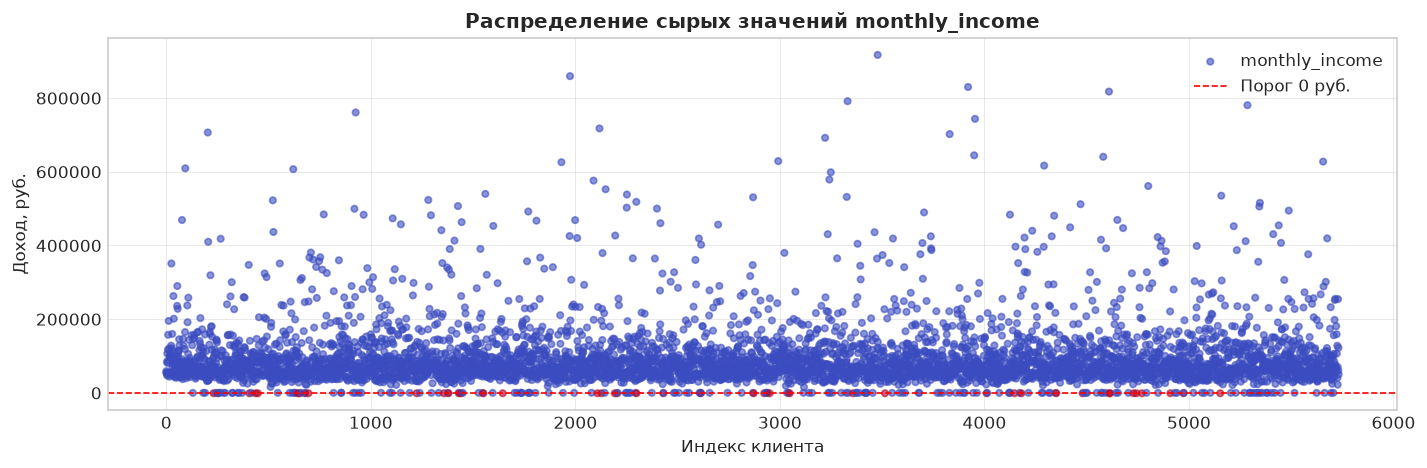

In [7]:
CLIENTS_CATEGORICAL_COLS = ['gender', 'city', 'segment', 'loyalty_tier', 'card_type', 'has_mobile_app', 'marketing_opt_in']

for col in CLIENTS_CATEGORICAL_COLS:
    display(df_clients_raw[col].value_counts(dropna=False).to_frame('count'))

invalid_income = df_clients_raw[df_clients_raw['monthly_income'] < 0]

print(f'Найдено записей с monthly_income <= 0: {len(invalid_income)}')
display(invalid_income[['client_id', 'monthly_income', 'segment', 'city', 'income_source', 'branch_code']].head(10))

plt.figure(figsize=(12, 4))
plt.scatter(
    df_clients_raw.index,
    df_clients_raw['monthly_income'],
    alpha=0.6,
    s=15,
    c=df_clients_raw['monthly_income'] < 0,
    cmap='coolwarm',
    label='monthly_income'
)
plt.axhline(0, color='red', linestyle='--', linewidth=1, label='Порог 0 руб.')
plt.title('Распределение сырых значений monthly_income', fontsize=12, fontweight='bold')
plt.xlabel('Индекс клиента')
plt.ylabel('Доход, руб.')
plt.legend()
plt.tight_layout()

In [8]:
TXN_CATEGORICAL_COLS = ['currency', 'category', 'channel', 'status']

for col in TXN_CATEGORICAL_COLS:
    display(df_txn_raw[col].value_counts(dropna=False).to_frame('count'))

txn_dt_temp = pd.to_datetime(df_txn_raw['txn_datetime'], format='mixed')
print(f"\nДиапазон дат: с {txn_dt_temp.min()} по {txn_dt_temp.max()}")
print(f"Операций до 2024-01-01: {(txn_dt_temp < '2024-01-01').sum()}")
print(f"Операций после 2025-06-30: {(txn_dt_temp > '2025-06-30 23:59:59').sum()}")

,count
currency,
RUB,623129
USD,1251
EUR,1224


,count
category,
Продукты,165139
Транспорт,65761
Одежда и обувь,64493
АЗС,58127
Развлечения и досуг,53697
Кафе и рестораны,48234
Аптеки,45480
Онлайн-сервисы,43855
Связь и интернет,29465


,count
channel,
Карта,319523
СБП,108166
Токен,105570
Онлайн-банк,92345


,count
status,
успешно,605722
отклонено,12240
возврат,7642



Диапазон дат: с 2023-12-15 00:00:00 по 2026-08-04 13:29:31
Операций до 2024-01-01: 9
Операций после 2025-06-30: 88


### 2.4. Связь между таблицами

In [9]:
cids_clients = set(df_clients_raw['client_id'])
cids_txns = set(df_txn_raw['client_id'])

diff_tx_only = cids_txns - cids_clients
diff_cl_only = cids_clients - cids_txns

print(f"Клиентов в clients.csv: {len(cids_clients)}")
print(f"Клиентов в transactions.csv: {len(cids_txns)}")
print(f"Клиентов есть в transactions.csv, но нет в clients.csv: {len(diff_tx_only)} (совершили {df_txn_raw['client_id'].isin(diff_tx_only).sum()} транзакций)")
print(f"Клиентов есть в clients.csv, но нет в transactions.csv: {len(diff_cl_only)}")

Клиентов в clients.csv: 5678
Клиентов в transactions.csv: 5990
Клиентов есть в transactions.csv, но нет в clients.csv: 322 (совершили 26941 транзакций)
Клиентов есть в clients.csv, но нет в transactions.csv: 10


**Выводы по аудиту.**

- в обеих таблицах присутствуют дубликаты по id клиента (55 дублирующих записей, из которых 40 полных дубликатов) и по id транзакции (1500 дублирующих записей, из которых 1281 полный дубликат),
- в `transactions.csv` есть записи вне исследуемого периода,
- в `monthly_income` существуют записи с отрицательным доходом (равным -999),
- в `transactions.csv` есть клиенты, которых нет в `clients.csv` (необходимо удалить),
- в `city` существуют разные варианты записи городов (17 различных записей для 6 городов),
- в `category` существуют разные варианты записи категорий трат.

## 3. Препроцессинг

На каждое изменение — строка в журнале (раздел 4). Решение «оставить
как есть» тоже является решением и тоже попадает в журнал.

### 3.1. Типы, даты, числа

In [10]:
clients_clean = df_clients_raw.copy()
txn_clean = df_txn_raw.copy()

clients_clean['birth_date'] = pd.to_datetime(clients_clean['birth_date'], format='%Y-%m-%d', errors='coerce')
clients_clean['registration_date'] = pd.to_datetime(clients_clean['registration_date'], format='%d.%m.%Y', errors='coerce')
clients_clean['card_open_date'] = pd.to_datetime(clients_clean['card_open_date'], format='%d.%m.%Y', errors='coerce')

bool_map = {'Да': True, 'Нет': False}

clients_clean['has_mobile_app'] = (
    clients_clean['has_mobile_app'].map(bool_map).astype('boolean')
)
clients_clean['marketing_opt_in'] = (
    clients_clean['marketing_opt_in'].map(bool_map).astype('boolean')
)

txn_clean['txn_id'] = txn_clean['txn_id'].astype(str)

### 3.2. Категориальные признаки

In [11]:
city_mapping = {
    'Москва': 'Москва', 'г. Москва': 'Москва', ' МОСКВА ': 'Москва', ' москва': 'Москва', 'МОСКВА': 'Москва', 'москва': 'Москва',
    'Санкт-Петербург': 'Санкт-Петербург', 'СПб': 'Санкт-Петербург', 'г. Санкт-Петербург': 'Санкт-Петербург', 'Санкт Петербург': 'Санкт-Петербург',
    'Нижний Новгород': 'Нижний Новгород', 'Н. Новгород': 'Нижний Новгород',
    'Казань': 'Казань', 'казань': 'Казань',
    'Новосибирск': 'Новосибирск', 'г. Новосибирск': 'Новосибирск',
    'Екатеринбург': 'Екатеринбург', 'ЕКАТЕРИНБУРГ': 'Екатеринбург', 'г.Екатеринбург': 'Екатеринбург'
}
n_city_variants = int((clients_clean['city'] != clients_clean['city'].str.strip().map(city_mapping)).sum())
clients_clean['city'] = clients_clean['city'].str.strip().map(lambda x: city_mapping.get(x, x))
print(f"Нормализовано строк городов: {n_city_variants}. Распределение городов:\n", clients_clean['city'].value_counts())

clients_categorical = ['gender', 'city', 'segment', 'card_type', 'income_source', 'branch_code']
clients_clean[clients_categorical] = clients_clean[clients_categorical].astype('category')

LOYALTY_ORDER = ['Базовый', 'Серебро', 'Золото', 'Платина']
clients_clean['loyalty_tier'] = pd.Categorical(clients_clean['loyalty_tier'], categories=LOYALTY_ORDER, ordered=True)

SATISFACTION_ORDER = [1, 2, 3, 4, 5]
clients_clean['satisfaction_score'] = pd.Categorical(clients_clean['satisfaction_score'], categories=SATISFACTION_ORDER, ordered=True)


category_mapping = {
    'Кафе/рестораны': 'Кафе и рестораны',
    'кафе и рестораны': 'Кафе и рестораны',
    'Связь и Интернет': 'Связь и интернет'
}
n_cat_changed = int(txn_clean['category'].isin(category_mapping.keys()).sum())
txn_clean['category'] = txn_clean['category'].replace(category_mapping)
print(f"\nНормализовано категорий транзакций: {n_cat_changed}. Распределение категорий:\n", txn_clean['category'].value_counts())

tx_categorical = ['currency', 'category', 'channel', 'status', 'mcc_code']
txn_clean[tx_categorical] = txn_clean[tx_categorical].astype('category')

Нормализовано строк городов: 1597. Распределение городов:
 city
Москва             1629
Санкт-Петербург    1000
Нижний Новгород     993
Новосибирск         744
Казань              688
Екатеринбург        679
Name: count, dtype: int64

Нормализовано категорий транзакций: 51353. Распределение категорий:
 category
Продукты               165139
Кафе и рестораны        80236
Транспорт               65761
Одежда и обувь          64493
АЗС                     58127
Развлечения и досуг     53697
Связь и интернет        48816
Аптеки                  45480
Онлайн-сервисы          43855
Name: count, dtype: int64


### 3.3. Пропуски

In [12]:
import pandas as pd

target_cols = ['monthly_income', 'satisfaction_score', 'app_last_login']
total_rows = len(df_clients_raw)

summary_data = []

for col in target_cols:
  nan_count = df_clients_raw[col].isna().sum()

  sentinel_count = (
      (df_clients_raw[col] == -999.0).sum()
      if pd.api.types.is_numeric_dtype(df_clients_raw[col])
      else 0
  )
  total_missing = nan_count + sentinel_count
  pct = (total_missing / total_rows) * 100

  summary_data.append({
      'Признак': col,
      'Всего пропусков': total_missing,
      'Доля от общего числа (%)': round(pct, 2),
  })

df_missing_summary = pd.DataFrame(summary_data)
display(df_missing_summary)


clients_clean['monthly_income'] = clients_clean['monthly_income'].mask(clients_clean['monthly_income'] <= 0)

,Признак,Всего пропусков,Доля от общего числа (%)
0,monthly_income,576,10.05
1,satisfaction_score,3466,60.46
2,app_last_login,2208,38.51


Анализ пропусков:
- `monthly_income`: пропуски могли быть оставлены по причине отказа от распрытия дохода клиента, необходимо заменить на NaN значения "-999", а остальные оставить;
- `satisfaction_score`: пропущенные значения означают клиентов, кооторые не оставили оценку сервису, также оставляем;
- `app_last_login`: число пропусков совпадает с числом клиентов, которые не пользуются мобильным приложением, сохраняем.

### 3.4. Выбросы

Обнаружение и решение — это два разных шага. Сначала первый, потом второй.

C:\Users\nikit\AppData\Local\Temp\ipykernel_10872\418725878.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=clients_clean['segment'], y=clients_clean['monthly_income'], ax=axes[0], palette="Blues")


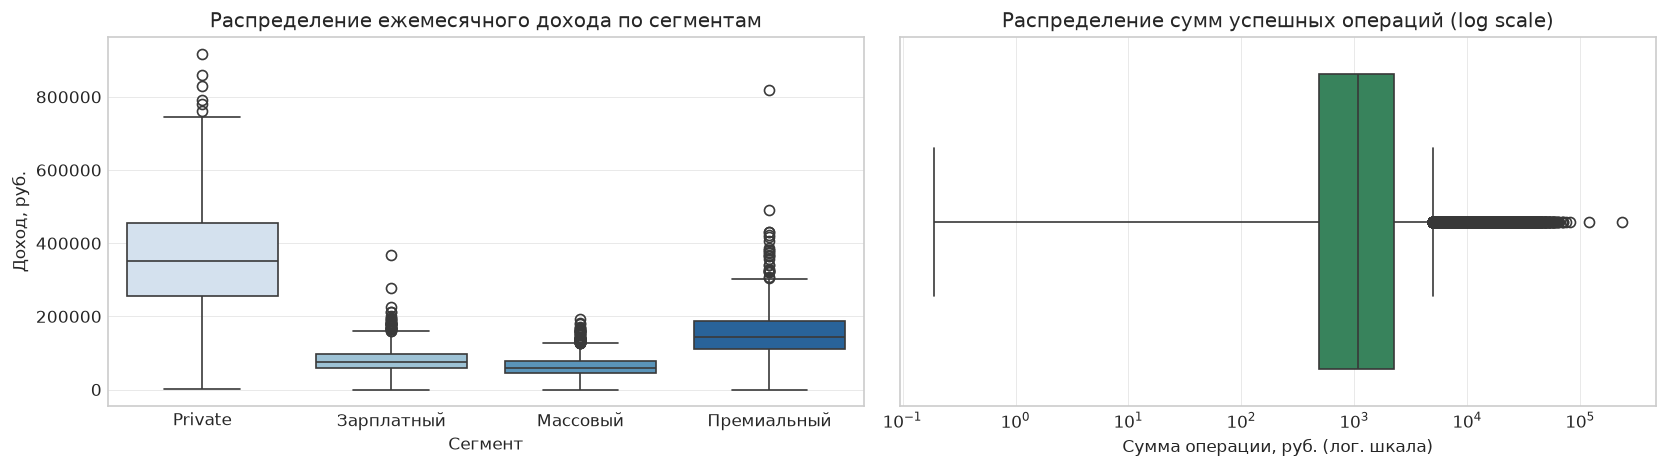

Квантили дохода: {0.5: 72500.0, 0.75: 107600.0, 0.95: 239019.99999999997, 0.99: 468059.9999999994, 1.0: 917200.0}
Квантили сумм операций: {0.5: 1077.52, 0.75: 2264.21, 0.95: 6359.355999999996, 0.99: 12468.444900000011, 1.0: 232471.13}


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.boxplot(x=clients_clean['segment'], y=clients_clean['monthly_income'], ax=axes[0], palette="Blues")
axes[0].set_title("Распределение ежемесячного дохода по сегментам")
axes[0].set_xlabel("Сегмент")
axes[0].set_ylabel("Доход, руб.")

succ_amts = txn_clean[txn_clean['status'] == 'успешно']['amount']
sns.boxplot(x=succ_amts, ax=axes[1], color="#2b8f5c")
axes[1].set_xscale("log")
axes[1].set_title("Распределение сумм успешных операций (log scale)")
axes[1].set_xlabel("Сумма операции, руб. (лог. шкала)")

plt.tight_layout()
plt.show()

print("Квантили дохода:", clients_clean['monthly_income'].quantile([0.5, 0.75, 0.95, 0.99, 1]).to_dict())
print("Квантили сумм операций:", succ_amts.quantile([0.5, 0.75, 0.95, 0.99, 1]).to_dict())

In [14]:
top_income = clients_clean.nlargest(20, 'monthly_income')
display(top_income[['client_id','monthly_income', 'segment', 'city', 'income_source']])

top_amounts = txn_clean.nlargest(20, 'amount')
display(top_amounts[['txn_id', 'client_id', 'txn_datetime', 'amount', 'currency', 'category', 'mcc_code', 'channel', 'status']])

,client_id,monthly_income,segment,city,income_source
3478,C002055,917200.0,Private,Екатеринбург,Зарплата в нашем банке
1974,C001609,859600.0,Private,Екатеринбург,Не указан
3920,C005533,830100.0,Private,Москва,Не указан
4609,C003627,817700.0,Премиальный,Москва,Зарплата в нашем банке
3331,C005378,791600.0,Private,Москва,Зарплата в другом банке
5286,C004185,780700.0,Private,Санкт-Петербург,Зарплата в другом банке
926,C005447,761000.0,Private,Екатеринбург,Не указан
3954,C004605,743700.0,Private,Москва,Зарплата в другом банке
2118,C000369,717700.0,Private,Санкт-Петербург,Зарплата в нашем банке
203,C002194,706700.0,Private,Санкт-Петербург,Зарплата в нашем банке


,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,channel,status
594047,698016,C003986,2025-05-31 23:40:15,232471.13,RUB,Одежда и обувь,5651,Карта,успешно
191336,290820,C001714,2024-06-17 09:21:32,125963.35,RUB,Одежда и обувь,5651,Токен,отклонено
180398,279919,C005552,2024-06-07 16:01:42,119935.20,RUB,Одежда и обувь,5651,Карта,успешно
580703,684698,C003686,2025-05-17 22:47:42,81520.44,RUB,АЗС,5541,Карта,успешно
293721,392953,C004185,2024-09-06 17:02:28,77909.98,RUB,Одежда и обувь,5651,Карта,отклонено
35185,135110,C002440,2024-02-07 14:11:32,76612.95,RUB,Одежда и обувь,5651,СБП,отклонено
566838,670858,C003916,2025-05-03 14:11:25,74639.28,RUB,Одежда и обувь,5651,Токен,успешно
491098,589810,C004327,2025-02-18 11:53:10,70714.50,RUB,Одежда и обувь,5651,Онлайн-банк,успешно
127450,227116,C002014,2024-04-22 20:32:56,69844.35,RUB,Одежда и обувь,5651,Карта,успешно
337370,436491,C001441,2024-10-11 10:02:09,68382.68,RUB,Одежда и обувь,5651,Онлайн-банк,успешно


На графике из пункта 2.3 (для monthly_income) красным цветом выделены люди с доходом "-999", а также рядом с ними есть еще некоторая категория людей. Рассмотрев поподробнее, можно сказать, что это люди, у которых доход записан в тысячах рублей (понятным это становится, если брать во внимание поля `segment` и `loyalty_tier`).

Найдено записей в тысячах рублей: 165


,client_id,monthly_income,city,segment,loyalty_tier
0,C004075,62.1,Москва,Массовый,Базовый
1,C005133,101.4,Новосибирск,Премиальный,Золото
2,C005188,113.8,Москва,Зарплатный,Золото
3,C001575,78.1,Москва,Зарплатный,Базовый
4,C005318,66.6,Нижний Новгород,Массовый,Базовый
5,C005784,402.3,Москва,Private,Платина
6,C001191,39.9,Екатеринбург,Зарплатный,Базовый
7,C004395,216.0,Екатеринбург,Премиальный,Золото
8,C001276,62.1,Новосибирск,Зарплатный,Базовый
9,C002002,49.2,Санкт Петербург,Массовый,Базовый


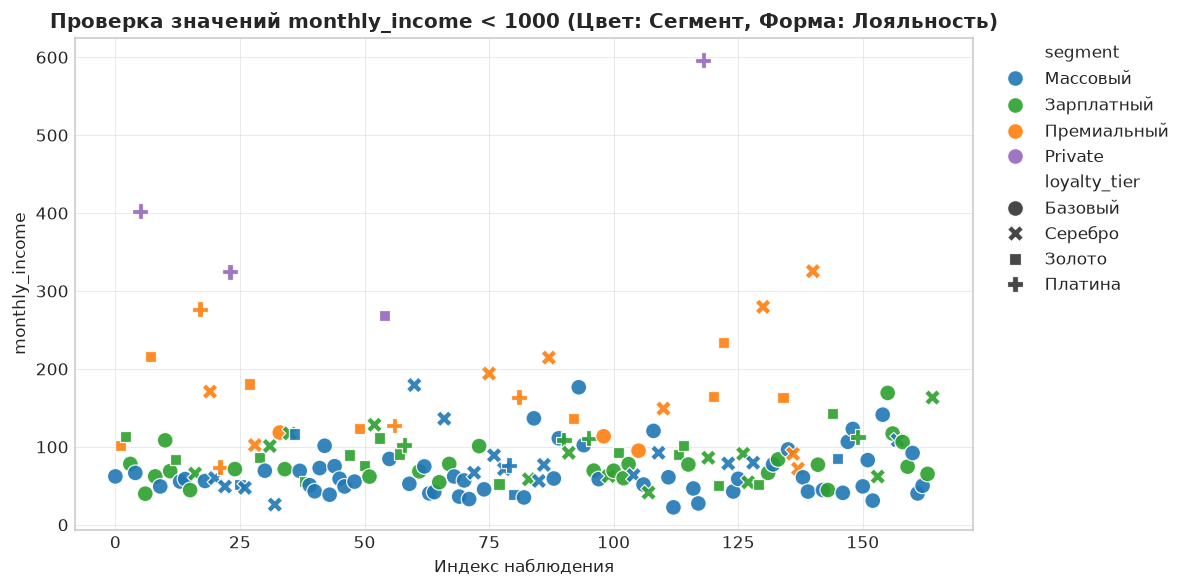

In [15]:
small_inc = df_clients_raw[(df_clients_raw['monthly_income'] > 0) & (df_clients_raw['monthly_income'] < 5000)].copy()
small_inc = small_inc.reset_index(drop=True)
small_inc['index_plot'] = small_inc.index

print(f'Найдено записей в тысячах рублей: {len(small_inc)}')
display(small_inc[['client_id', 'monthly_income', 'city', 'segment', 'loyalty_tier']].head(10))

plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=small_inc,
    x='index_plot',
    y='monthly_income',
    hue='segment',
    hue_order=['Массовый', 'Зарплатный', 'Премиальный', 'Private'],
    style='loyalty_tier',
    style_order=['Базовый', 'Серебро', 'Золото', 'Платина'],
    palette={
        'Массовый': '#1f77b4',
        'Зарплатный': '#2ca02c',
        'Премиальный': '#ff7f0e',
        'Private': '#9467bd',
    },
    s=90,
    alpha=0.9,
)

plt.title(
    'Проверка значений monthly_income < 1000 (Цвет: Сегмент, Форма:'
    ' Лояльность)',
    fontsize=12,
    fontweight='bold',
)
plt.xlabel('Индекс наблюдения', fontsize=10)
plt.ylabel('monthly_income', fontsize=10)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)
plt.tight_layout()
plt.show()

### 3.5. Фильтры, применяемые перед расчётом активности

Покажите воронку: сколько строк на входе и сколько осталось после каждого фильтра.

In [16]:
n_cl_before = len(clients_clean)
clients_clean = clients_clean.drop_duplicates()
n_cl_0 = len(clients_clean)

clients_clean = clients_clean.drop_duplicates(subset=['client_id'], keep=False)
n_cl_1 = len(clients_clean)

clients_clean['monthly_income'] = clients_clean['monthly_income'].replace(-999.0, np.nan)
mask_income_thousands = (clients_clean['monthly_income'] > 0) & (clients_clean['monthly_income'] < 1000)
n_income_fixed = int(mask_income_thousands.sum())
clients_clean.loc[mask_income_thousands, 'monthly_income'] = (clients_clean.loc[mask_income_thousands, 'monthly_income'] * 1000)


n_tx_before = len(txn_clean)
txn_clean = txn_clean.sort_values(by='txn_datetime', key=lambda col: col.str.len(), ascending=False).drop_duplicates(subset='txn_id', keep='first')
txn_clean['txn_datetime'] = pd.to_datetime(txn_clean['txn_datetime'], format='mixed')
n_tx_0 = len(txn_clean)

txn_clean = txn_clean[txn_clean['currency'] == 'RUB'].copy()
n_tx_1 = len(txn_clean)

mask_period = (txn_clean['txn_datetime'] >= '2024-01-01') & (txn_clean['txn_datetime'] <= '2025-06-30 23:59:59')
n_outside_dates = int((~mask_period).sum())
txn_clean = txn_clean[mask_period].copy()
n_tx_2 = len(txn_clean)

txn_clean = txn_clean[txn_clean['status'] == 'успешно'].copy()
n_tx_3 = len(txn_clean)

valid_cids = set(clients_clean['client_id'])
txn_clean = txn_clean[txn_clean['client_id'].isin(valid_cids)].copy()
n_tx_4 = len(txn_clean)

active_cids_in_period = set(txn_clean['client_id'])
clients_active = clients_clean[
    clients_clean['client_id'].isin(active_cids_in_period)
].copy()
n_cl_2 = len(clients_active)

funnel_clients_df = pd.DataFrame({
    'Шаг воронки': [
        '1. Удаление полных дубликатов строк',
        '2. Удаление конфликтующих дубликатов (client_id)',
        '3. Клиенты с "успешно" в нужном периоде',
    ],
    'Число строк': [n_cl_0, n_cl_1, n_cl_2],
    'Исключено строк': [n_cl_before - n_cl_0, n_cl_0 - n_cl_1, n_cl_1 - n_cl_2],
    'Доля от исходных, %': [
        round(n_cl_0 / n_cl_before * 100, 2),
        round(n_cl_1 / n_cl_before * 100, 2),
        round(n_cl_2 / n_cl_before * 100, 2),
    ],
})

funnel_txn_df = pd.DataFrame({
    'Шаг воронки': [
        '1. Удаление дубликатов транзакций',
        '2. Только рублевые операции (currency == RUB)',
        '3. Установление периода ',
        '4. Оставили только успешные покупки',
        '5. Удаление транзакций неизвестных клиентов',
    ],
    'Число строк': [n_tx_0, n_tx_1, n_tx_2, n_tx_3, n_tx_4],
    'Исключено строк': [
        n_tx_before - n_tx_0,
        n_tx_0 - n_tx_1,
        n_tx_1 - n_tx_2,
        n_tx_2 - n_tx_3,
        n_tx_3 - n_tx_4,
    ],
    'Доля от исходных, %': [
        round(n_tx_0 / n_tx_before * 100, 2),
        round(n_tx_1 / n_tx_before * 100, 2),
        round(n_tx_2 / n_tx_before * 100, 2),
        round(n_tx_3 / n_tx_before * 100, 2),
        round(n_tx_4 / n_tx_before * 100, 2),
    ],
})
display(funnel_clients_df)
display(funnel_txn_df)

,Шаг воронки,Число строк,Исключено строк,"Доля от исходных, %"
0,1. Удаление полных дубликатов строк,5693,40,99.30
1,2. Удаление конфликтующих дубликатов (client_id),5663,30,98.78
2,"3. Клиенты с ""успешно"" в нужном периоде",5653,10,98.60


,Шаг воронки,Число строк,Исключено строк,"Доля от исходных, %"
0,1. Удаление дубликатов транзакций,624104,1500,99.76
1,2. Только рублевые операции (currency == RUB),621637,2467,99.37
2,3. Установление периода,621540,97,99.35
3,4. Оставили только успешные покупки,601798,19742,96.19
4,5. Удаление транзакций неизвестных клиентов,574363,27435,91.81


In [17]:
clients_clean.info()

<class 'pandas.DataFrame'>
Index: 5663 entries, 0 to 5732
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   client_id           5663 non-null   str           
 1   birth_date          5663 non-null   datetime64[us]
 2   gender              5663 non-null   category      
 3   city                5663 non-null   category      
 4   segment             5663 non-null   category      
 5   loyalty_tier        5663 non-null   category      
 6   card_type           5663 non-null   category      
 7   registration_date   5663 non-null   datetime64[us]
 8   card_open_date      5663 non-null   datetime64[us]
 9   income_source       5663 non-null   category      
 10  monthly_income      5093 non-null   float64       
 11  has_mobile_app      5663 non-null   boolean       
 12  app_last_login      3479 non-null   str           
 13  satisfaction_score  2240 non-null   category      
 14  branch_c

In [18]:
clients_clean.describe().T.round(2)

,count,mean,min,25%,50%,75%,max,std
birth_date,5663,1971-10-16 11:26:33.713579,1936-07-30 00:00:00,1963-02-07 12:00:00,1973-06-21 00:00:00,1982-02-19 00:00:00,2002-06-30 00:00:00,NaN
registration_date,5663,2017-08-24 22:13:27.345929,2010-01-01 00:00:00,2015-03-20 12:00:00,2017-08-08 00:00:00,2020-01-15 00:00:00,2025-04-18 00:00:00,NaN
card_open_date,5663,2020-09-08 03:36:54.162105,2016-01-01 00:00:00,2018-05-04 00:00:00,2020-08-17 00:00:00,2022-12-16 00:00:00,2025-05-16 00:00:00,NaN
monthly_income,5093.0,98209.837031,15600.0,54400.0,74400.0,109000.0,917200.0,82736.704797


In [19]:
txn_clean.info()

<class 'pandas.DataFrame'>
Index: 574363 entries, 32 to 575670
Data columns (total 9 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   txn_id        574363 non-null  str           
 1   client_id     574363 non-null  str           
 2   txn_datetime  574363 non-null  datetime64[us]
 3   amount        574363 non-null  float64       
 4   currency      574363 non-null  category      
 5   category      574363 non-null  category      
 6   mcc_code      574363 non-null  category      
 7   channel       574363 non-null  category      
 8   status        574363 non-null  category      
dtypes: category(5), datetime64[us](1), float64(1), str(2)
memory usage: 24.6 MB


In [20]:
txn_clean.describe().T.round(2)

,count,mean,min,25%,50%,75%,max,std
txn_datetime,574363,2024-09-27 19:10:38.637235,2024-01-01 00:00:00,2024-05-20 18:57:11,2024-09-26 09:20:27,2025-02-02 19:11:06.500000,2025-06-30 23:59:35,NaN
amount,574363.0,1893.427643,3.13,488.17,1085.33,2275.915,232471.13,2610.92644


## 4. Журнал изменений

Одна строка — одно решение, а не одна запись. Колонки: `field`, `issue`,
`scope`, `n_rows`, `value_before`, `action`, `value_after`, `rationale`.

In [21]:
log_records = [
    {
        'field': (
            'birth_date, registration_date, card_open_date, app_last_login'
        ),
        'issue': 'Хранение календарных дат в строковом формате object',
        'scope': 'clients.csv, все строки',
        'n_rows': 5733,
        'value_before': 'Строки форматов YYYY-MM-DD, DD.MM.YYYY, YYYY-MM',
        'action': 'изменение типа',
        'value_after': 'datetime64[ns]',
        'rationale': (
            'Обеспечение корректной работы с датами'
        ),
    },
    {
        'field': 'has_mobile_app, marketing_opt_in',
        'issue': 'Хранение бинарных флагов в текстовом виде («Да» / «Нет»)',
        'scope': 'clients.csv, все строки',
        'n_rows': 5733,
        'value_before': "Строковые значения 'Да', 'Нет'",
        'action': 'изменение типа',
        'value_after': 'boolean (True / False)',
        'rationale': (
            'Стандартизация логических признаков и оптимизация памяти'
        ),
    },
    {
        'field': 'city',
        'issue': (
            'Разнобой написания городов'
        ),
        'scope': 'clients.csv, строки с ненормализованным написанием',
        'n_rows': 1597,
        'value_before': '17 различных текстовых вариантов написания',
        'action': 'исправление',
        'value_after': '6 правильных написаний городов',
        'rationale': (
            'Стандартизация категорий под один вид'
        ),
    },
    {
        'field': 'gender, segment, card_type, income_source, city, branch_code',
        'issue': (
            'Неэффективное использование памяти'
        ),
        'scope': 'clients.csv, все строки',
        'n_rows': 5733,
        'value_before': 'object (5 полей) и int64 (branch_code)',
        'action': 'изменение типа',
        'value_after': 'category',
        'rationale': (
            'Оптимизация памяти'
        ),
    },
    {
        'field': 'loyalty_tier',
        'issue': (
            'Отсутствие порядка у порядковой шкалы'
        ),
        'scope': 'clients.csv, все строки',
        'n_rows': 5733,
        'value_before': 'object',
        'action': 'изменение типа',
        'value_after': (
            'category (ordered=True: Базовый < Серебро < Золото < Платина)'
        ),
        'rationale': (
            'Обеспечение естественной сортировки'
        ),
    },
    {
        'field': 'satisfaction_score',
        'issue': (
            'float64 для порядковой шкалы'
        ),
        'scope': 'clients.csv, все строки',
        'n_rows': 5733,
        'value_before': 'float64',
        'action': 'изменение типа',
        'value_after': 'category',
        'rationale': (
            'Как минимум, теперь не считается среднее для порядковой шкалы'
        ),
    },
    {
        'field': 'category',
        'issue': (
            'Несогласованность названий категорий операций'
        ),
        'scope': 'transactions.csv, вариативные написания',
        'n_rows': 51353,
        'value_before': (
            '«Кафе/рестораны» (16 111), «кафе и рестораны» (15 891), «Связь и'
            ' Интернет» (19 351)'
        ),
        'action': 'исправление',
        'value_after': (
            'теперь 9 категорий трат как в ТЗ'
        ),
        'rationale': (
            'Стандартизация категорий под один вид'
        ),
    },
    {
        'field': 'category, channel, status, currency, mcc_code',
        'issue': (
            'Неэффективное использование памяти'
        ),
        'scope': 'transactions.csv, все строки',
        'n_rows': 624104,
        'value_before': 'object, int64 (mcc_code)',
        'action': 'изменение типа',
        'value_after': 'category',
        'rationale': (
            'Оптимизация памяти'
        ),
    },
    {
        'field': 'monthly_income',
        'issue': (
            'Естественные пропуски данных о доходе'
        ),
        'scope': 'clients.csv, явные NaN и -999.0',
        'n_rows': 576,
        'value_before': '534 явных NaN + 42 значения -999.0 (10.05% базы)',
        'action': 'оставлено',
        'value_after': 'NaN',
        'rationale': (
            'Клиент не предоставил справку/декларацию; искусственное заполнение медианой/средним исказит форму распределения доходов по сегментам'
        ),
    },
    {
        'field': 'satisfaction_score',
        'issue': (
            'Пропуски оценки удовлетворенности'
        ),
        'scope': 'clients.csv, строки с пропущенной оценкой',
        'n_rows': 3466,
        'value_before': 'NaN (60.46% базы)',
        'action': 'оставлено',
        'value_after': 'NaN',
        'rationale': (
            'Клиенты не проходли опрос'
        ),
    },
    {
        'field': 'app_last_login',
        'issue': (
            'Пропуски даты входа в мобильный банк (клиенты без приложения либо'
            ' не заходившие в него)'
        ),
        'scope': 'clients.csv, строки с отсутствующей датой логина',
        'n_rows': 2208,
        'value_before': 'NaN (38.51% базы)',
        'action': 'оставлено',
        'value_after': 'NaT',
        'rationale': (
            'Клиенты без приложения либо не заходившие в него'
        ),
    },
    {
        'field': 'amount',
        'issue': (
            'Крупные покупки'
        ),
        'scope': 'transactions.csv, строки с amount > 50 000 руб.',
        'n_rows': 33,
        'value_before': 'Транзакции от 50 200.00 до 232 471.13 руб.',
        'action': 'оставлено',
        'value_after': 'Исходные значения',
        'rationale': (
            'Траты похожи на валидные и приходятся на категории «Электроника», «Путешествия», «Одежда и обувь»'
        ),
    },
    {
        'field': 'monthly_income',
        'issue': (
            'Высокие доходы'
        ),
        'scope': 'clients.csv, строки с monthly_income > 300 000 руб.',
        'n_rows': 218,
        'value_before': 'Доходы от 300 000 до 917 200 руб.',
        'action': 'оставлено',
        'value_after': 'Исходные значения',
        'rationale': (
            'Значения полностью согласуются с принадлежностью клиентов к'
            ' сегментам «Премиальный» и «Private»'
        ),
    },
    {
        'field': 'client_id',
        'issue': 'Полные дубликаты строк в реестре клиентов',
        'scope': 'clients.csv, 40 строк повторов',
        'n_rows': 40,
        'value_before': 'Повторяющиеся записи по всем полям',
        'action': 'удалено',
        'value_after': 'Оставлен 1 уникальный экземпляр каждой строки',
        'rationale': (
            'Повторы завышают размер клиентской базы'
        ),
    },
    {
        'field': 'client_id',
        'issue': (
            'Конфликтующие записи: одинаковый client_id с разными городами и сегментами'
        ),
        'scope': 'clients.csv, 15 пар ID (30 строк)',
        'n_rows': 30,
        'value_before': 'Неоднозначные атрибуты профиля под одним ключом',
        'action': 'удалено',
        'value_after': 'Записи исключены из реестра',
        'rationale': (
            'Невозможно достоверно определить актуальный профиль клиента'
        ),
    },
    {
        'field': 'monthly_income',
        'issue': 'Доход -999.0',
        'scope': 'clients.csv, строки с monthly_income == -999.0',
        'n_rows': 42,
        'value_before': '-999.0',
        'action': 'исправлено',
        'value_after': 'np.nan',
        'rationale': (
            'Значение -999.0, скорее всего,  является технической заглушкой; замена на NaN предотвращает искажение статистик'
        ),
    },
    {
        'field': 'monthly_income',
        'issue': (
            'Несоответствие единиц измерения'
        ),
        'scope': 'clients.csv, строки с 0 < monthly_income < 1000',
        'n_rows': 165,
        'value_before': 'Значения от 15.6 до 402.3',
        'action': 'исправлено',
        'value_after': 'Значения умножены на 1 000',
        'rationale': (
            'Доход заполнен в тыс. руб., а в таблице единица измерения в руб.; по сегменту и лояльности подходят'
        ),
    },
    {
        'field': 'txn_id',
        'issue': (
            'Дубликаты первичного ключа транзакций (полные копии и строки с разной детализацией времени)'
        ),
        'scope': 'transactions.csv, строки с повторяющимся txn_id',
        'n_rows': 1500,
        'value_before': (
            '1 500 строк (в т.ч. 219 транзакций с дублированием даты без секунд)'
        ),
        'action': 'удалено',
        'value_after': (
            'Сохранена запись с более точным временем'
        ),
        'rationale': (
            'Удаление дубликатов при сохранении максимальной хронологической точности'
        ),
    },
    {
        'field': 'txn_datetime',
        'issue': (
            'Хранение календарных дат в строковом формате object'
        ),
        'scope': 'transactions.csv, все строки удаления дубликатов',
        'n_rows': 624104,
        'value_before': 'Строки YYYY-MM-DD и YYYY-MM-DD HH:MM:SS',
        'action': 'изменение типа',
        'value_after': 'datetime64[ns]',
        'rationale': (
            'Обеспечение корректной работы с датами'
        ),
    },
    {
        'field': 'currency',
        'issue': (
            'Операции в иностранной валюте без курса на дату операции'
        ),
        'scope': "transactions.csv, операции в долларах и евро",
        'n_rows': 2467,
        'value_before': '1 251 операция USD, 1 224 операции EUR',
        'action': 'удалено',
        'value_after': 'Оставлены только операции в RUB',
        'rationale': (
            'Сложение номиналов USD/EUR с рублевыми суммами искажает денежный оборот'
        ),
    },
        {
        'field': 'txn_datetime',
        'issue': (
            'Смешанный формат даты и времени (с секундами и без) в виде строки'
            ' object'
        ),
        'scope': 'transactions.csv, все строки после дедупликации',
        'n_rows': 624104,
        'value_before': 'Строки YYYY-MM-DD и YYYY-MM-DD HH:MM:SS',
        'action': 'изменение типа',
        'value_after': 'datetime64[ns]',
        'rationale': (
            'Возможность фильтрации по временным интервалам, агрегации по'
            ' месяцам и выделения окон активности'
        ),
    },
    {
        'field': 'txn_datetime',
        'issue': (
            'Транзакции за пределами исследуемого периода'
        ),
        'scope': 'transactions.csv, даты < 2024-01-01 или > 2025-06-30',
        'n_rows': 97,
        'value_before': '9 операций за 2023 г., 88 операций за вторую половину 2025–2026 гг.',
        'action': 'удалено',
        'value_after': (
            'Оставлены операии совершенные с 01.01.2024 по 30.06.2025'
        ),
        'rationale': (
            'Границы исследования зафиксированы техническим заданием'
        ),
    },
    {
        'field': 'status',
        'issue': (
            'Неуспешные финансовые операции'
        ),
        'scope': "transactions.csv, status в ['отклонено', 'возврат']",
        'n_rows': 19782,
        'value_before': (
            '12 240 операций «отклонено», 7 542 операции «возврат»'
        ),
        'action': 'удалено',
        'value_after': 'Оставлены только фактически завершенные покупки',
        'rationale': (
            'Отмененные операции не формируют оборот'
        ),
    },
    {
        'field': 'client_id',
        'issue': (
            'Транзакции клиентов, отсутствующих в clients'
        ),
        'scope': (
            'transactions.csv, операции неизвестных ID'
        ),
        'n_rows': 27435,
        'value_before': '27 435 транзакций по невалидным client_id',
        'action': 'удалено',
        'value_after': 'Оставлены транзакции только подтвержденных клиентов'
        ' банка',
        'rationale': (
            'По этим транзакциям нельзя найти клиента для кампании'
        ),
    },
    {
        'field': 'client_id',
        'issue': (
            'Клиентские профили с нулевой транзакционной активностью в исследуемом периоде'
        ),
        'scope': (
            'clients_clean, клиенты без транзакций в исследуемом периоде'
        ),
        'n_rows': 10,
        'value_before': '10 клиентов с 0 операций',
        'action': 'оставлено',
        'value_after': (
            'Исключены из расчетной базы активности (в справочнике клиентов сохранены)'
        ),
        'rationale': (
            'По клиентам без истории транзакций невозможно вычислить динамику спада, но профили валидны для базы'
        ),
    },
]


columns_order=["field", "issue", "scope", "n_rows", "value_before", "action", "value_after", "rationale",]
cleaning_log = pd.DataFrame(log_records)[columns_order]

## 5. Разведочный анализ

Графиков столько, сколько нужно. В отчёт пойдут не все.

### 5.1. Распределения количественных признаков

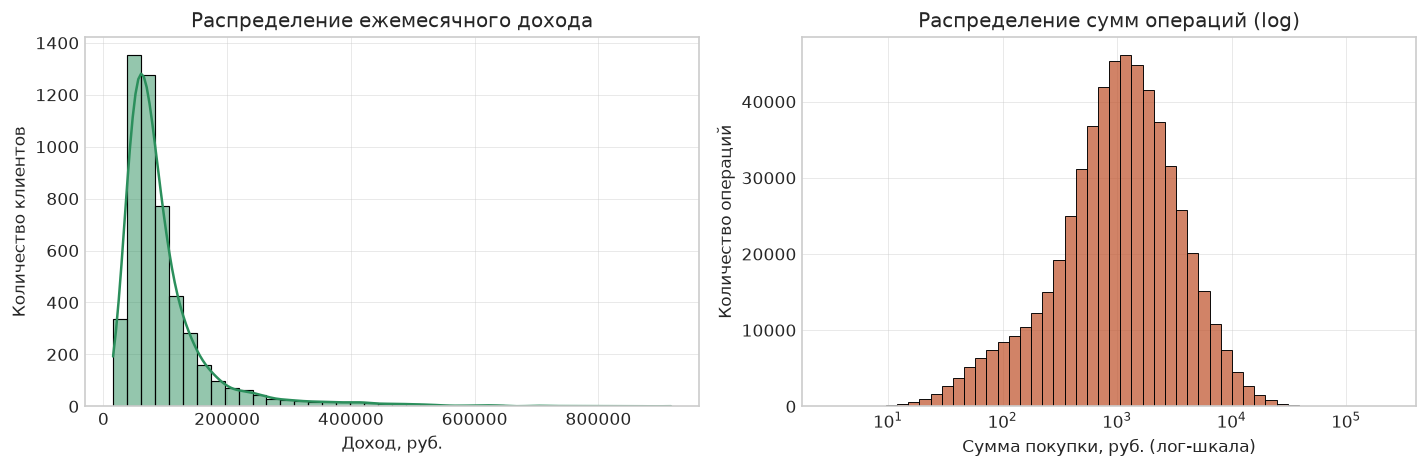

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(clients_clean['monthly_income'].dropna(), bins=40, kde=True, ax=axes[0], color="#2b8f5c")
axes[0].set_title("Распределение ежемесячного дохода")
axes[0].set_xlabel("Доход, руб.")
axes[0].set_ylabel("Количество клиентов")

sns.histplot(txn_clean['amount'], bins=50, ax=axes[1], color="#c25934", log_scale=True)
axes[1].set_title("Распределение сумм операций (log)")
axes[1].set_xlabel("Сумма покупки, руб. (лог-шкала)")
axes[1].set_ylabel("Количество операций")

plt.tight_layout()
plt.show()

### 5.2. Частотные характеристики категориальных признаков

C:\Users\nikit\AppData\Local\Temp\ipykernel_10872\1837212525.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=seg_counts.index, y=seg_counts.values, ax=axes[0, 0], palette="Blues_r")
C:\Users\nikit\AppData\Local\Temp\ipykernel_10872\1837212525.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=app_counts.index, y=app_counts.values, ax=axes[0, 1], palette="Greens_r")
C:\Users\nikit\AppData\Local\Temp\ipykernel_10872\1837212525.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=ch_counts.index, y=ch_counts.values, ax=axes[1, 0], p

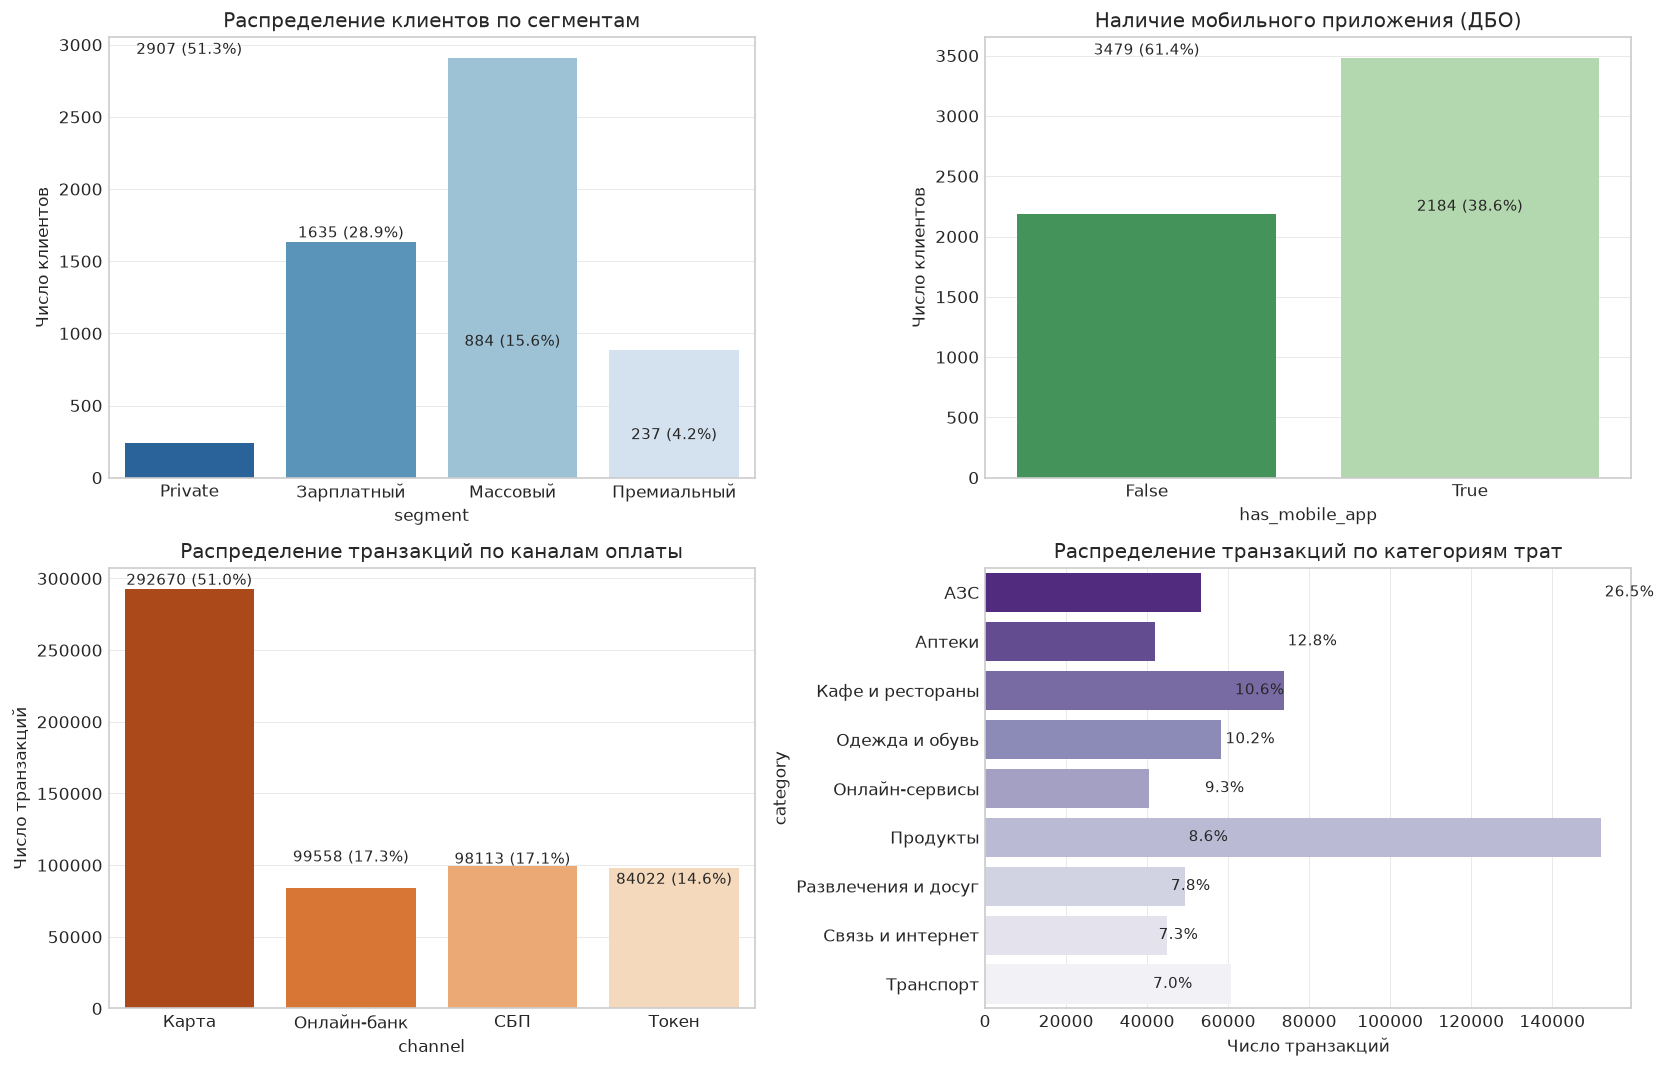

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

seg_counts = clients_clean['segment'].value_counts()
sns.barplot(x=seg_counts.index, y=seg_counts.values, ax=axes[0, 0], palette="Blues_r")
axes[0, 0].set_title("Распределение клиентов по сегментам")
axes[0, 0].set_ylabel("Число клиентов")
for i, v in enumerate(seg_counts.values):
    axes[0, 0].text(i, v + 30, f"{v} ({v/len(clients_clean)*100:.1f}%)", ha='center', fontsize=9)

app_counts = clients_clean['has_mobile_app'].value_counts()
sns.barplot(x=app_counts.index, y=app_counts.values, ax=axes[0, 1], palette="Greens_r")
axes[0, 1].set_title("Наличие мобильного приложения (ДБО)")
axes[0, 1].set_ylabel("Число клиентов")
for i, v in enumerate(app_counts.values):
    axes[0, 1].text(i, v + 30, f"{v} ({v/len(clients_clean)*100:.1f}%)", ha='center', fontsize=9)

ch_counts = txn_clean['channel'].value_counts()
sns.barplot(x=ch_counts.index, y=ch_counts.values, ax=axes[1, 0], palette="Oranges_r")
axes[1, 0].set_title("Распределение транзакций по каналам оплаты")
axes[1, 0].set_ylabel("Число транзакций")
for i, v in enumerate(ch_counts.values):
    axes[1, 0].text(i, v + 3000, f"{v} ({v/len(txn_clean)*100:.1f}%)", ha='center', fontsize=9)

cat_counts = txn_clean['category'].value_counts()
sns.barplot(y=cat_counts.index, x=cat_counts.values, ax=axes[1, 1], palette="Purples_r")
axes[1, 1].set_title("Распределение транзакций по категориям трат")
axes[1, 1].set_xlabel("Число транзакций")
for i, v in enumerate(cat_counts.values):
    axes[1, 1].text(v + 1000, i, f"{v/len(txn_clean)*100:.1f}%", va='center', fontsize=9)

plt.tight_layout()
plt.show()

### 5.3. Динамика по месяцам

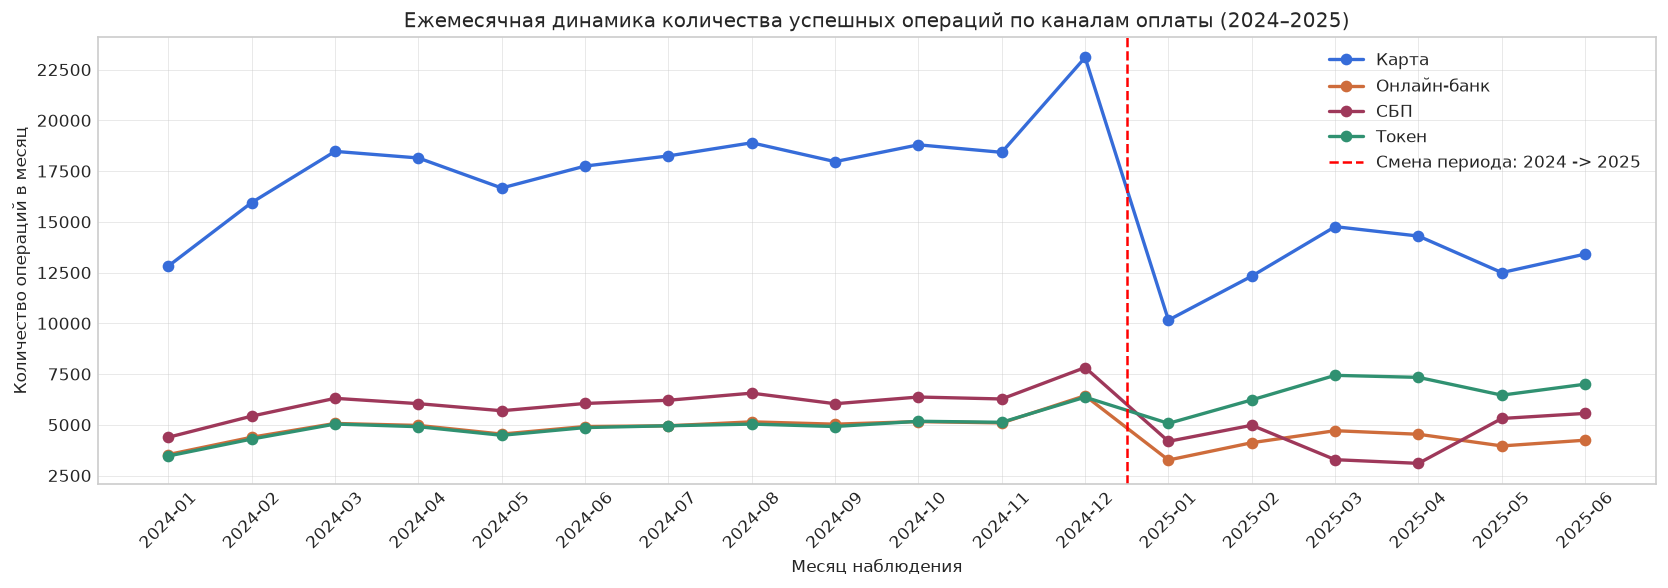

,Канал,Среднемес. 2024,Среднемес. 2025,"Изменение, %"
0,Карта,17935.00,12908.33,-28.03
2,СБП,6096.00,4401.00,-27.81
1,Онлайн-банк,4933.92,4135.83,-16.18
3,Токен,4882.58,6587.00,34.91


In [30]:
txn_clean['ym'] = txn_clean['txn_datetime'].dt.to_period('M')
monthly_ch = txn_clean.groupby(['ym', 'channel']).size().unstack(fill_value=0)

plt.figure(figsize=(14, 5))
for col in monthly_ch.columns:
    plt.plot(monthly_ch.index.astype(str), monthly_ch[col], marker='o', label=col, linewidth=2)

plt.axvline(x=11.5, color='red', linestyle='--', label='Смена периода: 2024 -> 2025')
plt.title("Ежемесячная динамика количества успешных операций по каналам оплаты (2024–2025)")
plt.xlabel("Месяц наблюдения")
plt.ylabel("Количество операций в месяц")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

ch_comp = pd.DataFrame({
    'Канал': monthly_ch.columns,
    'Среднемес. 2024': monthly_ch.iloc[:12].mean().values,
    'Среднемес. 2025': monthly_ch.iloc[12:].mean().values
})
ch_comp['Изменение, %'] = (ch_comp['Среднемес. 2025'] - ch_comp['Среднемес. 2024']) / ch_comp['Среднемес. 2024'] * 100
display(ch_comp.sort_values('Изменение, %').round(2))

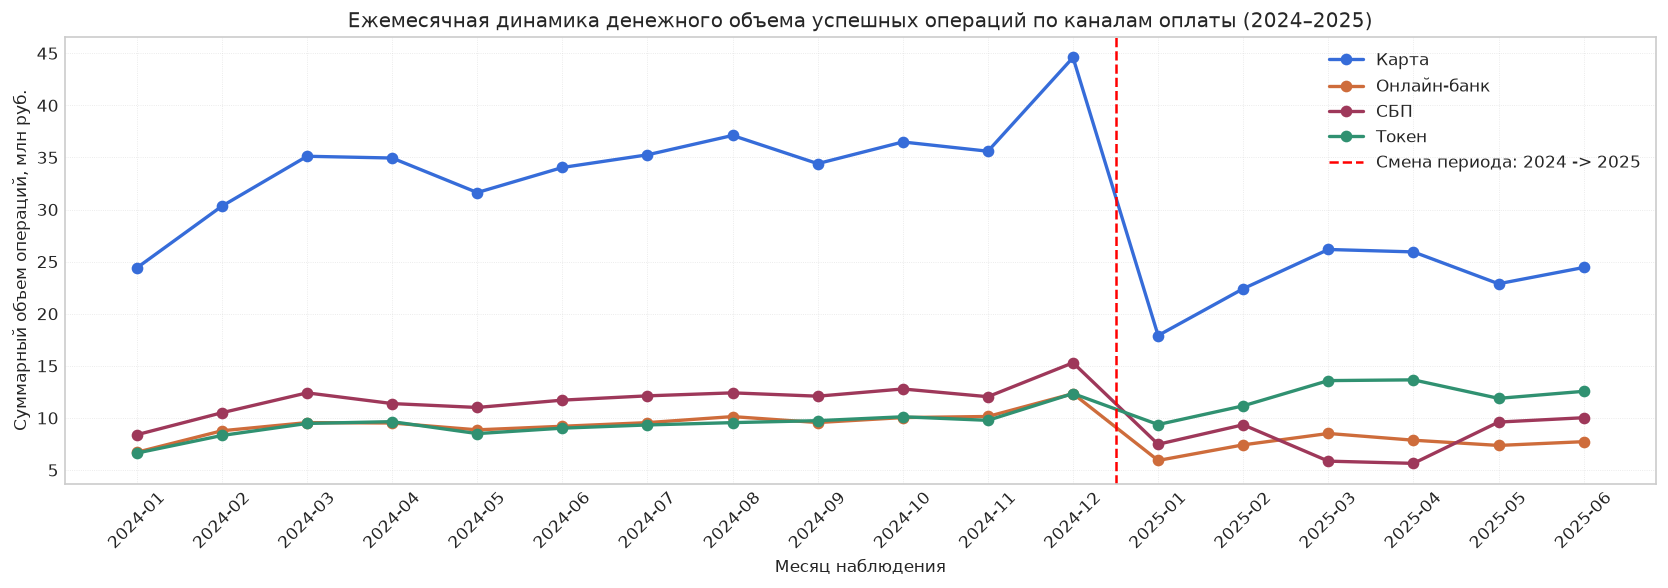

,Канал,Среднемес. 2024 (млн руб.),Среднемес. 2025 (млн руб.),"Изменение, %"
2,СБП,11.84,7.99,-32.54
0,Карта,34.49,23.29,-32.48
1,Онлайн-банк,9.53,7.47,-21.65
3,Токен,9.37,12.03,28.44


In [29]:
monthly_vol = (txn_clean.groupby(['ym', 'channel'])['amount'].sum().unstack(fill_value=0) / 1_000_000)

plt.figure(figsize=(14, 5))
for col in monthly_vol.columns:
    plt.plot(monthly_vol.index.astype(str), monthly_vol[col], marker='o', label=col, linewidth=2)

plt.axvline(x=11.5, color='red', linestyle='--', label='Смена периода: 2024 -> 2025')
plt.title('Ежемесячная динамика денежного объема успешных операций по каналам оплаты (2024–2025)'
)
plt.xlabel('Месяц наблюдения')
plt.ylabel('Суммарный объем операций, млн руб.')
plt.xticks(rotation=45)
plt.grid(True, linestyle=':', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

vol_comp = pd.DataFrame({
    'Канал': monthly_vol.columns,
    'Среднемес. 2024 (млн руб.)': monthly_vol.iloc[:12].mean().values,
    'Среднемес. 2025 (млн руб.)': monthly_vol.iloc[12:].mean().values,
})

vol_comp['Изменение, %'] = (vol_comp['Среднемес. 2025 (млн руб.)'] - vol_comp['Среднемес. 2024 (млн руб.)']) / vol_comp['Среднемес. 2024 (млн руб.)'] * 100

display(vol_comp.sort_values('Изменение, %').round(2))

### 5.4. Разрезы и связи между признаками

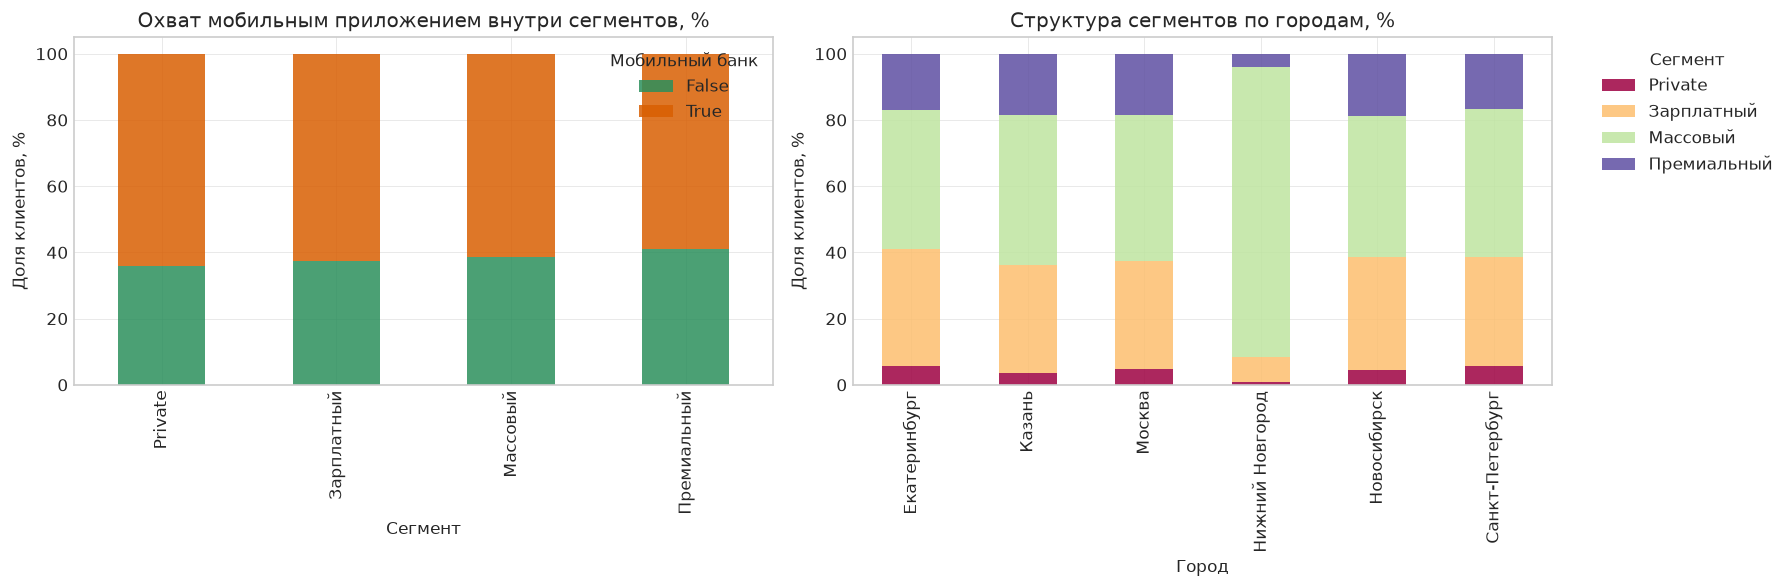

In [32]:
app_by_seg = pd.crosstab(clients_clean['segment'], clients_clean['has_mobile_app'], normalize='index') * 100

seg_by_city = pd.crosstab(clients_clean['city'], clients_clean['segment'], normalize='index') * 100

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
app_by_seg.plot(kind='bar', stacked=True, ax=axes[0], color=['#2b8f5c', '#d95f02'], alpha=0.85)
axes[0].set_title("Охват мобильным приложением внутри сегментов, %")
axes[0].set_ylabel("Доля клиентов, %")
axes[0].set_xlabel("Сегмент")
axes[0].legend(title="Мобильный банк")

seg_by_city.plot(kind='bar', stacked=True, ax=axes[1], colormap='Spectral', alpha=0.85)
axes[1].set_title("Структура сегментов по городам, %")
axes[1].set_ylabel("Доля клиентов, %")
axes[1].set_xlabel("Город")
axes[1].legend(title="Сегмент", bbox_to_anchor=(1.05, 1))

plt.tight_layout()
plt.show()

## 6. Метрика активности

Что именно вы считаете активностью, как она вычисляется, на каком
множестве клиентов, за какие окна. Отдельно: какое снижение эта метрика
**не увидит**.

За метрику активности в данной работе я выбрал среднемесячное количество успешных операций клиента. Эта величина равна количество операций N разделенных на некоторое количество месяцев m: $n_{tx} = N / m$.

По данной метрике (глядя на график из 5.3) видно то, что клиенты стали реже пользоваться картами. Она отражает привычку повседневного использования карты. Но, с другой стороны, по ней будет невозможно увидеть снижение среднего чека операции (например, платит только за проезд, а крупные траты проводит через банк-конкурент).


## 7. Поиск и описание групп

Правило отбора для каждой группы, её размер, причина падения.
Правило разрешения конфликтов, если клиент подходит под несколько групп.

### 7.1. Кого в кампанию не берём и почему

- Клиенты, не согласные на маркетинговую коммуникацию (нельзя по закону)
- Активные клиенты (у которых нет уменьшения использования услугами банка)
- Новые клиенты (не имеют сформировавшейся статистики, по ним нельзя сказать об оттоке)
- Неактивные клиенты (это карта для них - не основная, маловероятно их заинтересовать)
- Клиенты из `Премиального` и `Private` сегмента (для них нужен особый подход)

## 8. Что проверили и что не подтвердилось

Гипотезы, которые вы проверили и отвергли. По одной строке на гипотезу,
с числом.

## 9. Сохранение результатов

Три файла: очищенная таблица для второго ноутбука, журнал изменений,
итоговый список кампании.

In [ ]:
# clean_.to_csv("clean_data.csv", index=False)
# cleaning_log.to_csv("cleaning_log.csv", index=False, encoding="utf-8")
# campaign[["client_id", "group"]].to_csv("campaign_list.csv", index=False, encoding="utf-8")